![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
## **Aluno**: Adair J. Limana
## Desafio 1
---

## 1. Contexto

Um sistema público de saúde precisa **orçar o gasto do próximo ano** com medicamentos para diabetes. O governo subsidia esses medicamentos (programa **Pharmaceutical Benefit Scheme**, da Austrália), e o gasto mensal é registrado pelo órgão responsável (Medicare Australia).

Você faz parte da equipe de análise de dados e precisa entregar duas coisas: uma **previsão do gasto mensal dos próximos 12 meses**, e a **justificativa do modelo** escolhido para gerá-la.

Nas Aulas 1 e 2, você viu:

* como reconhecer tendência, sazonalidade e ruído em uma série temporal
* como **decompor** a série em tendência, sazonalidade e resíduo, nos modelos aditivo e multiplicativo
* como **suavizar** e prever com a suavização exponencial
* como separar treino e teste e medir o erro (MAE e RMSE) contra um baseline

Agora você vai aplicar tudo isso, de ponta a ponta, em uma série nova.

## 2. Objetivo

Prever o gasto mensal com medicamentos antidiabéticos nos 12 meses seguintes ao fim do histórico, e justificar a escolha do modelo.

Você deverá:

1. Carregar e explorar a série
2. Decompor a série e decidir entre o modelo aditivo e o multiplicativo
3. Separar treino e teste (os últimos 12 meses como teste)
4. Criar um baseline simples
5. Ajustar os modelos de suavização exponencial e compará-los no teste
6. Escolher o melhor modelo, ajustá-lo na série inteira e prever os próximos 12 meses
7. Calcular o orçamento do próximo ano e escrever a conclusão

## 3. Dataset: gasto mensal com medicamentos antidiabéticos

O dataset é o **a10**, do livro *Forecasting: Principles and Practice* (Hyndman e Athanasopoulos). Os dados originais são da Medicare Australia.

Características principais:

* **Valor:** gasto mensal do governo, em **milhões de dólares**
* **Período:** de julho de 1991 a junho de 2008 (204 meses, 17 anos completos)
* **Colunas:** `Month` (mês) e `Spending` (gasto)

O arquivo está no repositório da disciplina:

```
https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/datasets/a10_gasto_medicamentos.csv
```

## 4. Escopo e limitações

Para manter o desafio focado no que vimos até aqui, valem estas regras. Elas também são **assunto da sua apresentação**: comente o que cada limite significa para a decisão do orçamento.

1. A previsão é de **ponto**: um valor por mês, sem intervalo de confiança (os intervalos de previsão vêm nas aulas seguintes)
2. Não use **variáveis externas** (população, preço, política de subsídio): só a própria série
3. A validação é feita em **uma única janela**: os últimos 12 meses como teste
4. Os dados são mensais e o ciclo sazonal é **anual**
5. O baseline é o mais simples que vimos na aula
6. Use os métodos das Aulas 1 e 2. Não é preciso (nem esperado) usar modelos mais avançados

## 5. Tarefas

Você deverá realizar as seguintes tarefas, na ordem:

### 1. Carregar e explorar

Carregue o dataset e plote a série. Confira o período coberto, o número de meses e se há valores ausentes.

### 2. Decompor

Decomponha a série nos dois tipos de modelo (aditivo e multiplicativo). Plote os componentes e compare os resíduos dos dois.

### 3. Escolher o tipo de modelo

Com base na decomposição, decida se a sazonalidade da série é aditiva ou multiplicativa e **justifique com evidências** (gráficos e números).

### 4. Treino, teste e baseline

Reserve os últimos 12 meses como teste. Crie uma previsão de referência (baseline) e meça o erro dela com MAE e RMSE.

### 5. Modelos de suavização exponencial

Ajuste, no treino, os modelos de suavização exponencial vistos na aula. Meça o erro de cada um no teste e compare com o baseline.

### 6. Previsão final

Escolha o melhor modelo, ajuste-o com **todos** os dados e preveja os 12 meses seguintes (julho de 2008 a junho de 2009). Plote o histórico recente com a previsão.

### 7. Orçamento e conclusão

Calcule o gasto total previsto para o próximo ano e compare com o total dos últimos 12 meses do histórico. Escreva uma conclusão curta.

## Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

`PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [40]:
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'
SERIE_NAME = 'Pharmaceutical Benefit Scheme'
PERIOD = 12

## Parte 1: carregar e explorar

Carregue o dataset e plote a série. Deixe a série pronta para os modelos e confira o período, o número de meses e os valores ausentes.

In [41]:
df = pd.read_csv(PATH + 'datasets/a10_gasto_medicamentos.csv', parse_dates=['Month'], index_col='Month')
spending = df['Spending']
spending.head()

Month
1991-07-01    3.526591
1991-08-01    3.180891
1991-09-01    3.252221
1991-10-01    3.611003
1991-11-01    3.565869
Name: Spending, dtype: float64

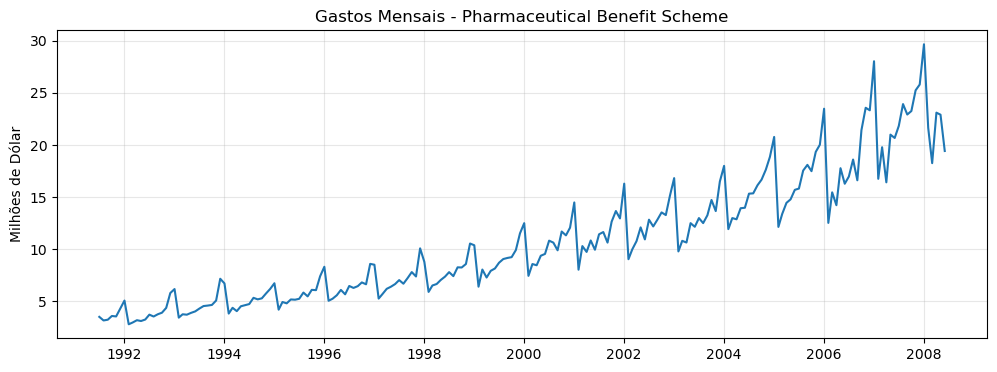

In [42]:
plt.figure(figsize=(12, 4))
plt.plot(spending.index, spending.values)
plt.title('Gastos Mensais - Pharmaceutical Benefit Scheme')
plt.ylabel('Milhões de Dólar')
plt.grid(alpha=0.3)
plt.show()

In [43]:
complete_spending = spending.asfreq('1MS')

print('Total de meses existentes no intervalo observado:', len(complete_spending))
print('Total de meses com dados coletados:', len(spending))

Total de meses existentes no intervalo observado: 204
Total de meses com dados coletados: 204


Não há necessidade de aplicar interpolação, pois **não** possui intervalos faltantes.

## Parte 2: decomposição

### Decomposição

#### Modelo Aditiva

In [44]:
additive_stl = STL(
    complete_spending,
    period=PERIOD,
    robust=True
).fit()

Os quatro componentes, cada um em um painel (série observada, tendência, sazonalidade e resíduo):

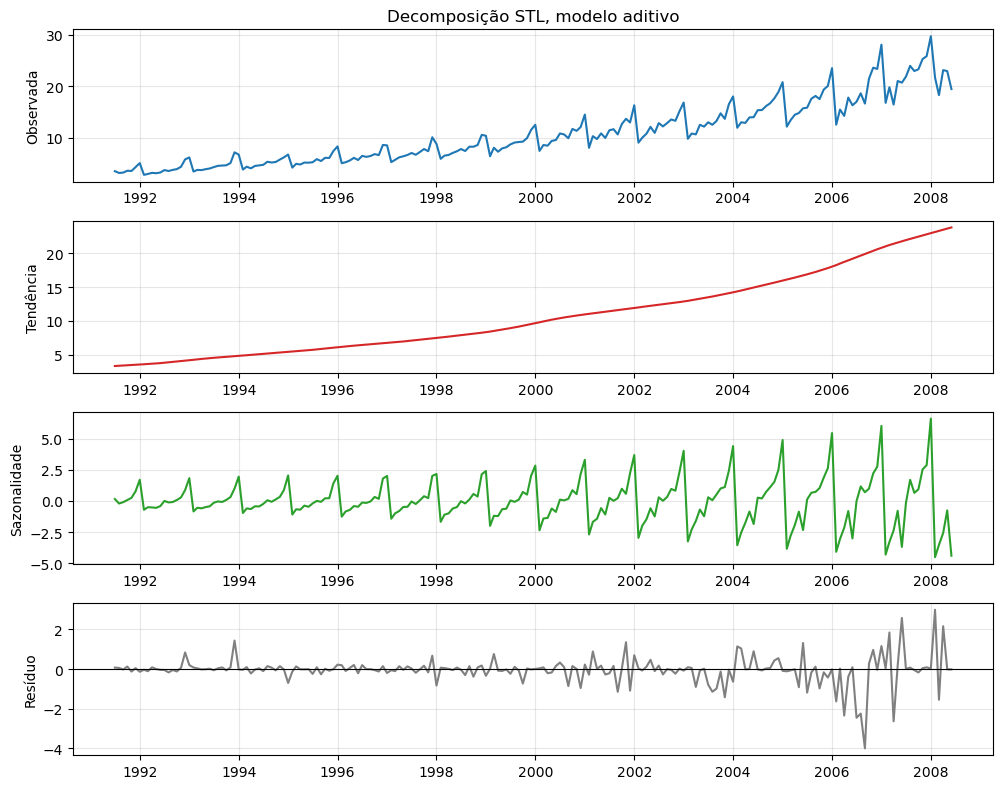

In [45]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8))
eixos[0].plot(additive_stl.observed, color='tab:blue')
eixos[0].set_title('Decomposição STL, modelo aditivo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(additive_stl.trend, color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(additive_stl.seasonal, color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(additive_stl.resid, color='gray')
eixos[3].axhline(0, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')

for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Modelo Multiplicativo

Para decompor uma série multiplicativa usando o método STL, é necessário transformar em uma série aditiva, para isso usamos a propriedades das funções logaritmas.

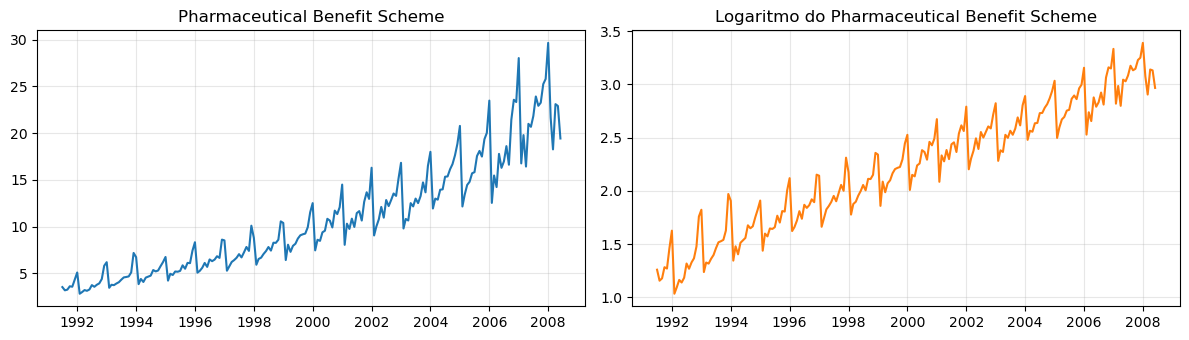

In [46]:
log_spending = np.log(complete_spending)

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
eixos[0].plot(complete_spending)
eixos[0].set_title(SERIE_NAME)
eixos[1].plot(log_spending, color='tab:orange')
eixos[1].set_title(f'Logaritmo do {SERIE_NAME}')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
multiplicative_stl = STL(log_spending, period=PERIOD, robust=True).fit()

Os quatro componentes, cada um em um painel (série observada, tendência, sazonalidade e resíduo):

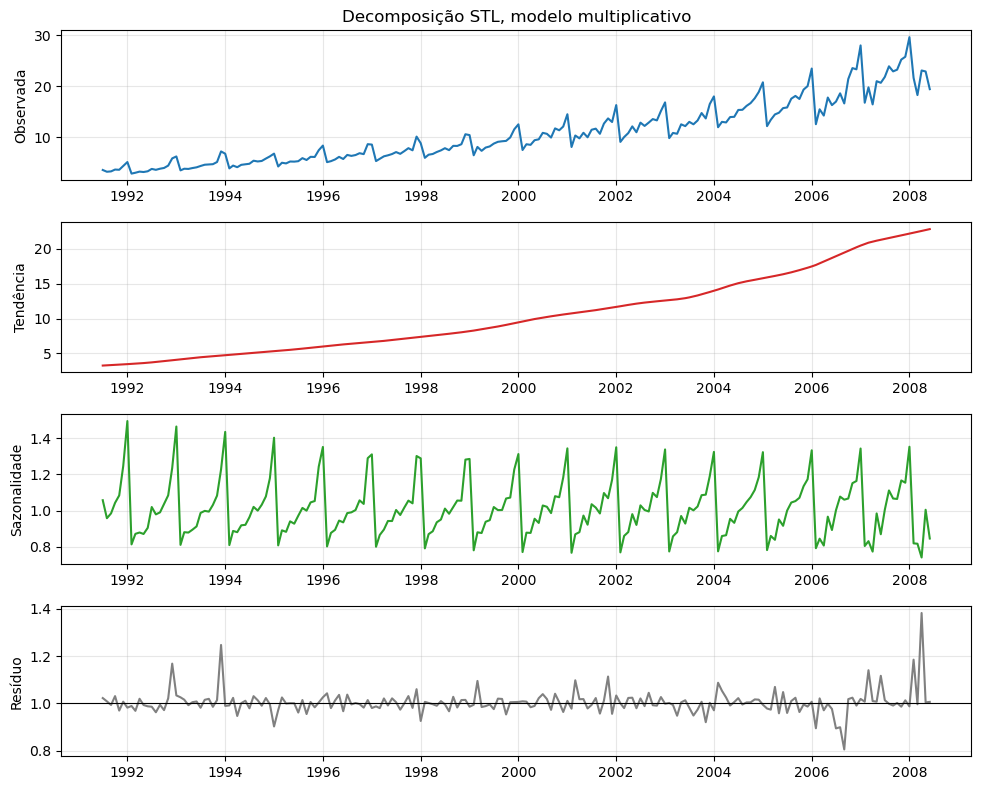

In [48]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8))
eixos[0].plot(np.exp(multiplicative_stl.observed), color='tab:blue')
eixos[0].set_title('Decomposição STL, modelo multiplicativo')
eixos[0].set_ylabel('Observada')
eixos[1].plot(np.exp(multiplicative_stl.trend), color='tab:red')
eixos[1].set_ylabel('Tendência')
eixos[2].plot(np.exp(multiplicative_stl.seasonal), color='tab:green')
eixos[2].set_ylabel('Sazonalidade')
eixos[3].plot(np.exp(multiplicative_stl.resid), color='gray')
eixos[3].axhline(1, color='black', linewidth=0.8)
eixos[3].set_ylabel('Resíduo')

for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Comparação do Resíduo

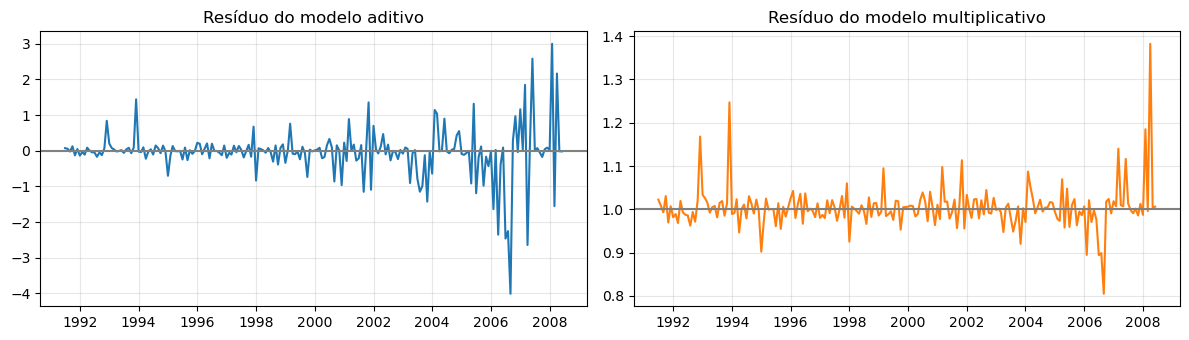

In [49]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
eixos[0].plot(additive_stl.resid)
eixos[0].axhline(0, color='gray')
eixos[0].set_title('Resíduo do modelo aditivo')
eixos[1].plot(np.exp(multiplicative_stl.resid), color='tab:orange')
eixos[1].axhline(1, color='gray')
eixos[1].set_title('Resíduo do modelo multiplicativo')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
print('Mediana do resíduo em valor absoluto | Aditivo:', round(additive_stl.resid.abs().median(), 3), '| Multiplicativo', round(np.exp(multiplicative_stl.resid).abs().median(), 3))

Mediana do resíduo em valor absoluto | Aditivo: 0.109 | Multiplicativo 1.002


No gráfico vemos:

* **Aditivo:** Possui mais pontos oscilando do valor base zero, e também com diferença de até 4 pontos.
* **Multiplicativo:** A diferença dos pontos que variam em relação ao valor base 1 é menor que 0.4 pontos.

O modelo **multiplicativo** descreve melhor a sazonalidade.

## Parte 3: escolha do tipo de modelo

Compare os resíduos dos dois modelos e decida se a sazonalidade é aditiva ou multiplicativa. Use gráficos e números como evidência.

In [51]:
year_groups = complete_spending.groupby(complete_spending.index.year)

resume = pd.DataFrame({
    'media': year_groups.mean(),
    'amplitude': year_groups.max() - year_groups.min(),
})

resume['amplitude / media'] = resume['amplitude'] / resume['media']

resume.round(3)

,media,amplitude,amplitude / media
Month,,,
1991,3.574,1.125,0.315
1992,3.807,2.996,0.787
1993,4.628,3.729,0.806
1994,5.068,2.890,0.570
1995,5.611,3.201,0.570
1996,6.450,3.537,0.548
1997,7.094,4.818,0.679
1998,7.776,4.641,0.597
1999,8.830,5.111,0.579


In [52]:
print('Amplitude em', resume.index[0], ':', round(resume['amplitude'].iloc[0], 3), '| em', resume.index[-1], ':', round(resume['amplitude'].iloc[-1], 3))
print('Média em', resume.index[0], ':', round(resume['media'].iloc[0], 3), '| em', resume.index[-1], ':', round(resume['media'].iloc[-1], 3))

Amplitude em 1991 : 1.125 | em 2008 : 11.4
Média em 1991 : 3.574 | em 2008 : 22.506


In [53]:
print('Amplitude / média: mínimo', round(resume['amplitude / media'].min(), 3), '| máximo', round(resume['amplitude / media'].max(), 3))

Amplitude / média: mínimo 0.315 | máximo 0.806


**Escreva aqui a sua decisão:** a sazonalidade é aditiva ou multiplicativa? Quais evidências sustentam a escolha?

A análise da decomposição STL indica que o modelo multiplicativo é mais adequado para representar a sazonalidade da série. Entre 1991 e 2008, a média aumentou de 3,574 para 22,506, enquanto a amplitude sazonal passou de 1,125 para 11,400. Embora não seja uma relação perfeitamente proporcionla, pois a razão entre a aplitude e média variou de 0,315 a 0,806, o crescimento expressivo da amplitude indica que as oscilações sazonais aumentam conforme o nível da série, comportamento característico de uma sazonalidade multiplicativa.

## Parte 4: treino, teste e baseline

Separe os últimos 12 meses como teste, crie o baseline e meça o erro dele no teste.

In [54]:
h = 12
print('Horizonte (h):', h, 'meses')

# [:-h]: todas as linhas, menos as h últimas
training = complete_spending.iloc[:-h]

# [-h:]: só as h últimas linhas
test = complete_spending.iloc[-h:]

training.tail()

Horizonte (h): 12 meses


Month
2007-02-01    16.763869
2007-03-01    19.792754
2007-04-01    16.427305
2007-05-01    21.000742
2007-06-01    20.681002
Freq: MS, Name: Spending, dtype: float64

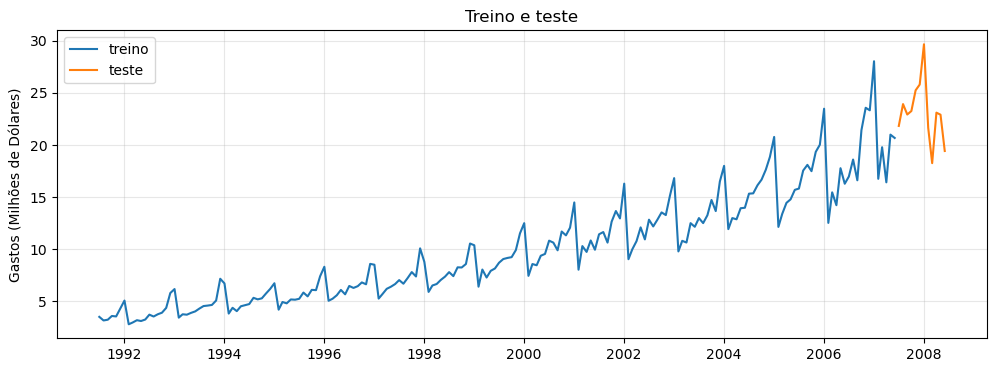

In [55]:
plt.figure(figsize=(12, 4))
plt.plot(training.index, training.values, label='treino')
plt.plot(test.index, test.values, color='tab:orange', label='teste')
plt.title('Treino e teste')
plt.ylabel('Gastos (Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

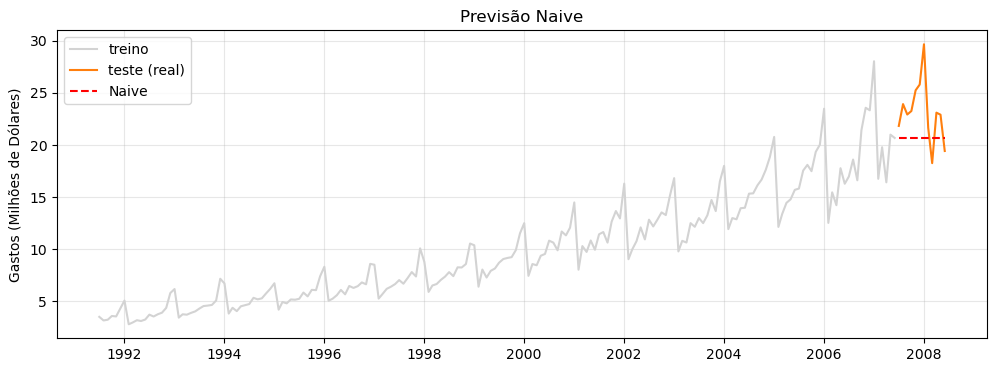

In [56]:
naive = pd.Series(training.iloc[-1], index=test.index)
naive.head()

plt.figure(figsize=(12, 4))
plt.plot(training.index, training.values, color='lightgray', label='treino')
plt.plot(test.index, test.values, color='tab:orange', label='teste (real)')
plt.plot(naive.index, naive.values, color='red', linestyle='--', label='Naive')
plt.title('Previsão Naive')
plt.ylabel('Gastos (Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [57]:
naive_error = test - naive
naive_error.head()

print('MAE do Naive:', round(naive_error.abs().mean(), 2))
print('RMSE do Naive:', round(np.sqrt((naive_error ** 2).mean()), 2))



MAE do Naive: 3.1
RMSE do Naive: 3.77


## Parte 5: suavização exponencial

Ajuste os modelos de suavização exponencial no treino e gere a previsão de 12 meses de cada um.

### Suavização exponencial simples (SES)

In [58]:
ses_model = SimpleExpSmoothing(training, initialization_method='estimated' )

ses_fit = ses_model.fit()
print('α estimado:', round(ses_fit.params['smoothing_level'], 3))

ses_prevision = ses_fit.forecast(h)
ses_prevision.round(1).head()

α estimado: 0.306


2007-07-01    20.2
2007-08-01    20.2
2007-09-01    20.2
2007-10-01    20.2
2007-11-01    20.2
Freq: MS, dtype: float64

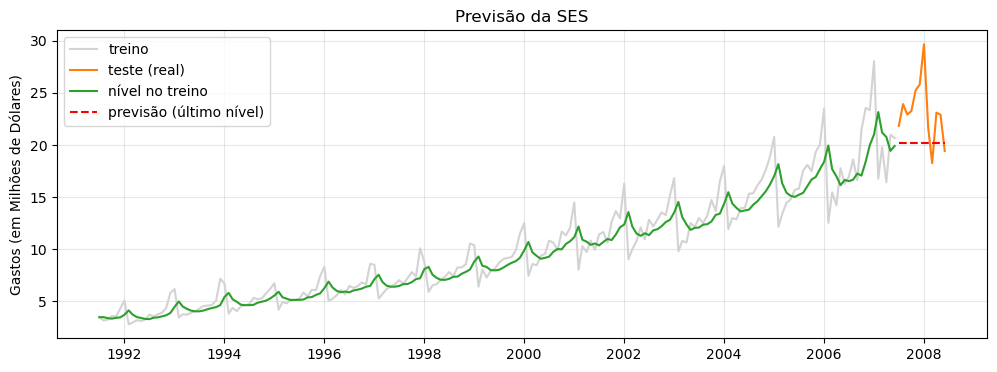

In [59]:
plt.figure(figsize=(12, 4))
plt.plot(training.index, training.values, color='lightgray', label='treino')
plt.plot(test.index, test.values, color='tab:orange', label='teste (real)')
plt.plot(ses_fit.fittedvalues.index, ses_fit.fittedvalues.values, color='tab:green', label='nível no treino')
plt.plot(ses_prevision.index, ses_prevision.values, color='red', linestyle='--', label='previsão (último nível)')
plt.title('Previsão da SES')
plt.ylabel('Gastos (em Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Método de Holt

In [60]:
holt_fit = Holt(training, initialization_method='estimated').fit()
print('α estimado:', round(holt_fit.params['smoothing_level'], 3))
print('β estimado:', round(holt_fit.params['smoothing_trend'], 3))

α estimado: 0.053
β estimado: 0.053


In [61]:
holt_prevision = holt_fit.forecast(h)
holt_prevision.round(1).head()

2007-07-01    20.4
2007-08-01    20.5
2007-09-01    20.7
2007-10-01    20.8
2007-11-01    21.0
Freq: MS, dtype: float64

In [62]:
print('Aumento por mês na previsão:', round(holt_prevision.diff().iloc[1], 2))

Aumento por mês na previsão: 0.16


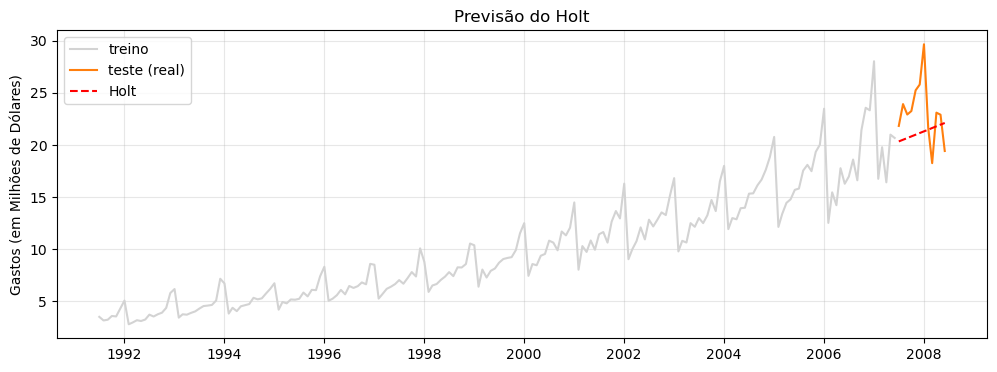

In [63]:
plt.figure(figsize=(12, 4))
plt.plot(training.index, training.values, color='lightgray', label='treino')
plt.plot(test.index, test.values, color='tab:orange', label='teste (real)')
plt.plot(holt_prevision.index, holt_prevision.values, color='red', linestyle='--', label='Holt')
plt.title('Previsão do Holt')
plt.ylabel('Gastos (em Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Holt-Winters

In [64]:
hw_fit = ExponentialSmoothing(
    training,
    trend='add',
    seasonal='mul',
    seasonal_periods=h,
    initialization_method='estimated',
).fit()
print('α estimado:', round(hw_fit.params['smoothing_level'], 3))
print('β estimado:', round(hw_fit.params['smoothing_trend'], 3))
print('γ estimado:', round(hw_fit.params['smoothing_seasonal'], 3))

α estimado: 0.259
β estimado: 0.051
γ estimado: 0.0


In [65]:
hw_prevision = hw_fit.forecast(h)
hw_prevision.round(1).head()

2007-07-01    21.6
2007-08-01    22.2
2007-09-01    22.1
2007-10-01    24.2
2007-11-01    25.3
Freq: MS, dtype: float64

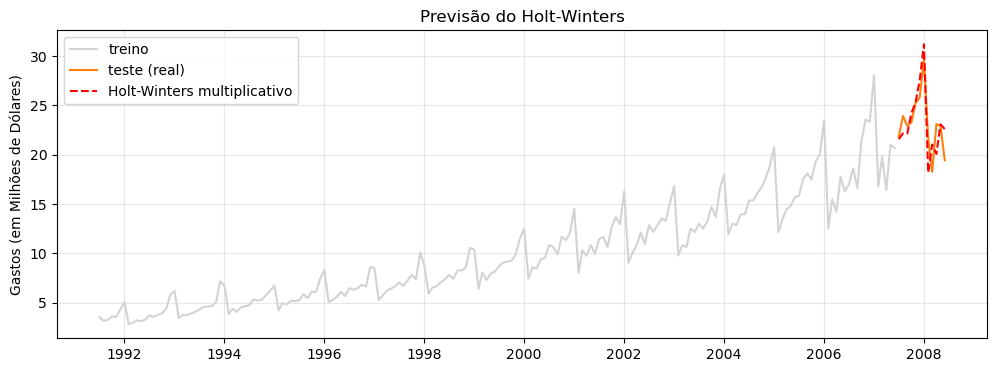

In [66]:
plt.figure(figsize=(12, 4))
plt.plot(training.index, training.values, color='lightgray', label='treino')
plt.plot(test.index, test.values, color='tab:orange', label='teste (real)')
plt.plot(hw_prevision.index, hw_prevision.values, color='red', linestyle='--', label='Holt-Winters multiplicativo')
plt.title('Previsão do Holt-Winters')
plt.ylabel('Gastos (em Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Parte 6: comparação dos modelos

Reúna as previsões, meça o erro de cada modelo no teste e plote as previsões contra o valor real.

In [67]:
forecasts = pd.DataFrame({
    'Naive': naive,
    'SES': ses_prevision,
    'Holt': holt_prevision,
    'HW multiplicativo': hw_prevision
})
forecasts.round(1).head()

,Naive,SES,Holt,HW multiplicativo
2007-07-01,20.7,20.2,20.4,21.6
2007-08-01,20.7,20.2,20.5,22.2
2007-09-01,20.7,20.2,20.7,22.1
2007-10-01,20.7,20.2,20.8,24.2
2007-11-01,20.7,20.2,21.0,25.3


In [68]:
errors = forecasts.rsub(
    # série de onde se subtrai a previsão: teste - previsão
    test,
    # 0: opera coluna a coluna, alinhando as linhas pelas datas
    axis=0,
)
errors.round(1).head()

,Naive,SES,Holt,HW multiplicativo
2007-07-01,1.2,1.7,1.5,0.3
2007-08-01,3.2,3.8,3.4,1.8
2007-09-01,2.2,2.8,2.3,0.8
2007-10-01,2.6,3.1,2.4,-0.9
2007-11-01,4.6,5.1,4.3,-0.1


In [69]:
table = pd.DataFrame({
    'MAE': errors.abs().mean(),
    'RMSE': np.sqrt((errors ** 2).mean())
})
table.round(2)

,MAE,RMSE
Naive,3.10,3.77
SES,3.45,4.14
Holt,2.95,3.60
HW multiplicativo,1.64,2.02


In [70]:
print('Menor MAE:', table['MAE'].idxmin(), '| valor:', round(table['MAE'].min(), 2))
print('Menor RMSE:', table['RMSE'].idxmin(), '| valor:', round(table['RMSE'].min(), 2))
print('MAE do Naive (baseline):', round(table.loc['Naive', 'MAE'], 2))

Menor MAE: HW multiplicativo | valor: 1.64
Menor RMSE: HW multiplicativo | valor: 2.02
MAE do Naive (baseline): 3.1


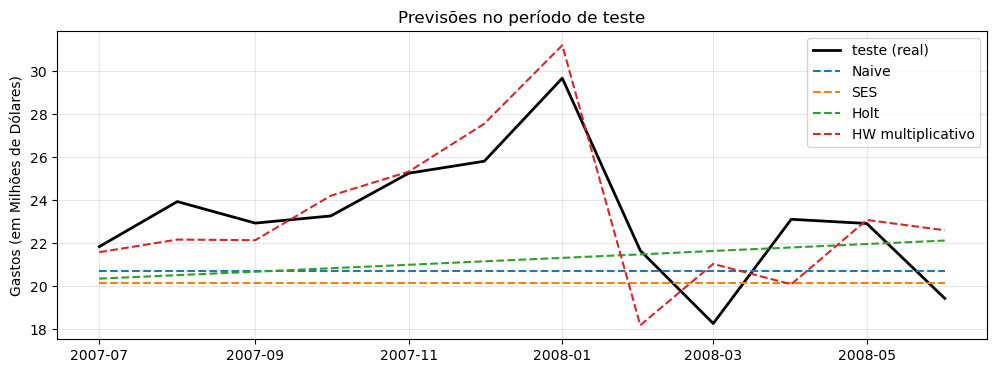

In [71]:
plt.figure(figsize=(12, 4))
plt.plot(test.index, test.values, color='black', linewidth=2, label='teste (real)')
for coluna in forecasts.columns:
    plt.plot(forecasts.index, forecasts[coluna], linestyle='--', label=coluna)
plt.title('Previsões no período de teste')
plt.ylabel('Gastos (em Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Parte 7: previsão final e orçamento

Com o melhor modelo escolhido, ajuste-o na **série inteira** e preveja os 12 meses seguintes (julho de 2008 a junho de 2009). Calcule o gasto total previsto e compare com o total dos últimos 12 meses.

In [72]:
complete_fit = ExponentialSmoothing(
    complete_spending,
    trend='add',
    seasonal='mul',
    seasonal_periods=12,
    initialization_method='estimated',
).fit()

In [73]:
complete_prevision = complete_fit.forecast(h)
complete_prevision.round(1).head()

2008-07-01    23.8
2008-08-01    24.8
2008-09-01    24.5
2008-10-01    26.3
2008-11-01    27.7
Freq: MS, dtype: float64

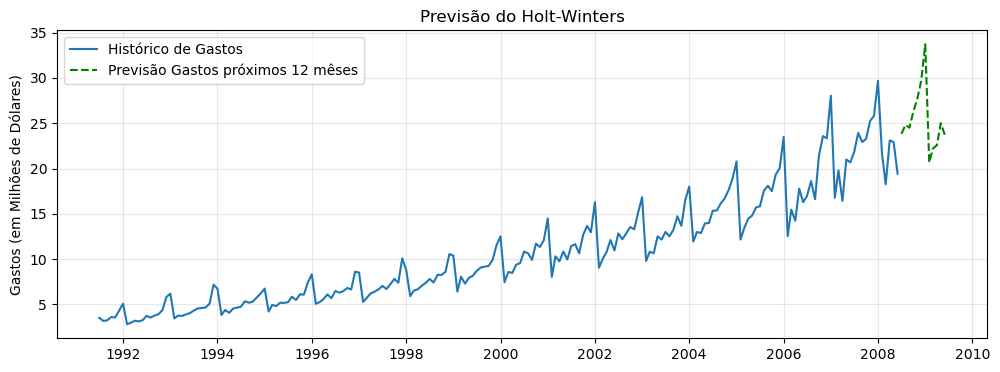

In [74]:
plt.figure(figsize=(12, 4))
plt.plot(complete_spending.index, complete_spending.values, label='Histórico de Gastos')
plt.plot(complete_prevision.index, complete_prevision.values, color='green', linestyle='--', label='Previsão Gastos próximos 12 mêses')
plt.title('Previsão do Holt-Winters')
plt.ylabel('Gastos (em Milhões de Dólares)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [75]:
print(f'Total de Gastos previstos nos próximos 12 meses ${complete_prevision.values.sum():.2f} Milhões')

print(f'Total de Gastos nos últimos 12 meses ${complete_spending[-h:].values.sum():.2f} Milhões')


Total de Gastos previstos nos próximos 12 meses $304.74 Milhões
Total de Gastos nos últimos 12 meses $278.05 Milhões


## Conclusão

Escreva uma conclusão curta, com:

1. O modelo escolhido e **por que** (decomposição e erro no teste)
2. O quanto ele melhora o baseline
3. O orçamento previsto para o próximo ano
4. As **limitações** do resultado (previsão de ponto, sem variáveis externas, um único ano de teste)

O modelo escolhido foi o Holt-Winters com sazonalidade multiplicativa. Embora a razão entre a amplitude e a média tenha variado de 0,315 a 0,806, a decomposição da série demonstra que a amplitude das oscilações aumenta conforme os gastos mensais crescem, justificando essa escolha. Em comparação ao modelo baseline, o Holt-Winters reduziu o erro médio absoluto (MAE) em 52,9%, prevendo um gasto total de US$ 304,74 milhões para os próximos 12 meses.

Apesar dos resultados positivos, o modelo apresenta algumas limitações: fornece apenas previsões pontuais, sem intervalos de confiança que permitam avaliar diretamente a incerteza das estimativas; não considera variáveis externas, como fatores econômicos ou eventos extraordinários, que podem comprometer sua precisão; e teve seu desempenho avaliado em apenas um ano de teste. Essa última limitação restringe a avaliação de sua capacidade de generalização, uma vez que os resultados podem depender das características específicas do período analisado.